In [72]:
# Source - https://stackoverflow.com/a
# Posted by user4720834
# Retrieved 2025-11-20, License - CC BY-SA 3.0

import os
os.environ["KMP_DUPLICATE_LIB_OK"]="TRUE"

import glob
import random
import numpy as np
from PIL import Image
from tqdm import tqdm
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset
import torchvision.transforms.functional as TF



In [73]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [74]:
import torch
print(torch.__version__)

2.9.0+cu126


In [75]:

# -------------------------------
# 랜덤 시드 고정
# -------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# -------------------------------
# 경로 설정
# -------------------------------
train_rgb_dir = "/content/drive/MyDrive/Colab Notebooks/2D Segmentation/Training/RGB"
train_label_dir = "/content/drive/MyDrive/Colab Notebooks/2D Segmentation/Training/Label"

val_rgb_dir = "/content/drive/MyDrive/Colab Notebooks/2D Segmentation/Validation/RGB"
val_label_dir = "/content/drive/MyDrive/Colab Notebooks/2D Segmentation/Validation/Label"

In [76]:
# -------------------------------
# 2. EDA 서브 함수
# -------------------------------
def get_image_paths(rgb_dir, label_dir):
    rgb_paths = sorted(glob.glob(os.path.join(rgb_dir, "*.png")))
    label_paths = sorted(glob.glob(os.path.join(label_dir, "*.png")))
    return rgb_paths, label_paths

def check_image_sizes(rgb_paths):
    sizes = [Image.open(p).size for p in rgb_paths]
    print("\nUnique image sizes:", set(sizes))
    return sizes

def compute_class_stats(label_paths, num_classes=13):
    class_counts = {i: 0 for i in range(num_classes)}
    for lp in tqdm(label_paths, desc="Counting class pixels"):
        mask = load_label(lp)
        unique, counts = np.unique(mask, return_counts=True)
        for u, c in zip(unique, counts):
            class_counts[u] += c

    total_pixels = sum(class_counts.values())
    if total_pixels == 0:
        raise ValueError("❌ 라벨 이미지에서 픽셀을 읽지 못했습니다.")

    class_ratio = {k: v / total_pixels * 100 for k, v in class_counts.items()}
    class_weights = 1.0 / np.log(1.02 + np.array([class_ratio[k]/100 for k in sorted(class_ratio.keys())]))

    return class_counts, class_ratio, class_weights

def plot_class_distribution(class_ratio, class_weights, label_paths):
    # 클래스 비율
    plt.figure(figsize=(8,4))
    plt.bar(class_ratio.keys(), class_ratio.values())
    plt.title("Class Distribution (%)")
    plt.xlabel("Class ID")
    plt.ylabel("Percent")
    plt.show()

    # 이미지별 클래스 다양성
    diversity = [len(np.unique(load_label(lp))) for lp in label_paths]
    plt.figure(figsize=(8,4))
    plt.hist(diversity, bins=range(1, 20))
    plt.title("Class Diversity Per Image")
    plt.xlabel("Unique classes per image")
    plt.ylabel("Count")
    plt.show()

    print("Average classes per image:", np.mean(diversity))
    print("\nSuggested class weights:", class_weights)

    # -------------------------------
# 3. 전체 EDA 실행
# -------------------------------
def run_full_eda(rgb_dir, label_dir, num_classes=13):
    rgb_paths, label_paths = get_image_paths(rgb_dir, label_dir)
    print("RGB images:", len(rgb_paths))
    print("Label images:", len(label_paths))

    check_image_sizes(rgb_paths)
    class_counts, class_ratio, class_weights = compute_class_stats(label_paths, num_classes)

    print("\nClass pixel ratio (%):")
    for k, v in class_ratio.items():
        print(f"Class {k}: {v:.3f}%")

    plot_class_distribution(class_ratio, class_weights, label_paths)

    # 데이터셋에 존재하는 라벨 값
    all_values = set()
    for lp in label_paths:
        all_values.update(np.unique(load_label(lp)))
    print("\nAll label values in dataset:", sorted(list(all_values)))

    return class_weights

In [77]:
import glob

# -------------------------------
# 전역 변수 설정
# -------------------------------
NUM_CLASSES = 13 # Colorize Mask 팔레트에 정의된 클래스 개수

# ====================================================================
# 1. 데이터셋 유틸리티 함수
# ====================================================================

def load_label(path):
    """
    라벨 이미지를 로드하고, RGB일 경우 첫 채널(인덱스)만 사용합니다.
    """
    raw = np.array(Image.open(path))
    if raw.ndim == 3:
        raw = raw[:, :, 0]
    return raw


#!! 크롭하기
def crop_small_object(image, mask, target_class_ids): #target_class_ids id리스
    """
    특정 클래스 ID(작은 객체)를 중심으로 이미지를 크롭하고 원본 크기로 리사이즈
    데이터 증강(Augmentation) 목적
    """
    mask_np = np.array(mask)
    # 목표 클래스에 해당하는 픽셀 좌표 찾기
    coords = np.argwhere(np.isin(mask_np, target_class_ids))

    if len(coords) == 0:
        return image, mask  # 작은 객체 없으면 그대로 반환

    # 객체의 최소/최대 좌표 (바운딩 박스)
    y1, x1 = coords.min(axis=0)
    y2, x2 = coords.max(axis=0)

    # 패딩 크기 계산 (객체 크기의 절반 또는 최소 10)
    h_pad = max(10, (y2 - y1)//2)
    w_pad = max(10, (x2 - x1)//2)

    # 크롭 영역 설정 (경계 검사 포함)
    y1 = max(0, y1 - h_pad)
    y2 = min(mask_np.shape[0], y2 + h_pad)
    x1 = max(0, x1 - w_pad)
    x2 = min(mask_np.shape[1], x2 + w_pad)

    # 크롭 및 원본 크기로 리사이즈
    image_cropped = image.crop((x1, y1, x2, y2)).resize(image.size, resample=Image.Resampling.BILINEAR)
    mask_cropped = mask.crop((x1, y1, x2, y2)).resize(mask.size, resample=Image.Resampling.NEAREST) # 마스크는 NEAREST 사용

    return image_cropped, mask_cropped

# -------------------------------
# Dataset 정의
# -------------------------------
class SegDataset(Dataset):
    def __init__(self, rgb_dir, label_dir, transform=None, small_obj_classes=None):
        self.rgb_paths = sorted(glob.glob(os.path.join(rgb_dir, "*.png")))
        self.label_paths = sorted(glob.glob(os.path.join(label_dir, "*.png")))
        self.transform = transform
        self.small_obj_classes = small_obj_classes


    def __len__(self):
        return len(self.rgb_paths)

    def __getitem__(self, idx):
        # Image.open(path) 시 mask에 대한 mode가 'P' 또는 'L'이 되어야 함
        image = Image.open(self.rgb_paths[idx]).convert("RGB")
        mask = Image.open(self.label_paths[idx])

        # 1. 작은 객체 중심 crop (Augmentation)
        if self.small_obj_classes:
            image, mask = crop_small_object(image, mask, self.small_obj_classes)

        # 2. 일반 Augmentation (transform)
        if self.transform:
            # 이미지와 마스크에 동일한 랜덤 변환 적용을 위한 시드 설정
            seed = np.random.randint(0, 10000)
            random.seed(seed)
            torch.manual_seed(seed)
            image = self.transform(image)

            random.seed(seed)
            torch.manual_seed(seed)
            mask = self.transform(mask)

        # 마스크를 LongTensor로 변환 (손실 함수에서 클래스 인덱스로 사용)
        mask = torch.as_tensor(np.array(mask), dtype=torch.long)

        return image, mask

# ====================================================================
# 2. 시각화 및 유틸리티 함수
# ====================================================================

def epoch_time(start_time, end_time):
    """
    에폭 소요 시간을 분/초로 계산합니다.
    """
    elapsed_time = end_time - start_time
    elapsed_mins = int(elapsed_time / 60)
    elapsed_secs = int(elapsed_time - (elapsed_mins * 60))
    return elapsed_mins, elapsed_secs

def colorize_mask(mask):
    """
    클래스 인덱스 마스크를 시각화를 위한 RGB 컬러 마스크로 변환합니다.
    """
    palette = np.array([
        [0, 0, 0],          # 0 None
        [70, 70, 70],       # 1 Buildings
        [190, 153, 153],    # 2 Fences
        [150, 120, 90],     # 3 Other
        [220, 20, 60],      # 4 Pedestrians
        [153, 153, 153],    # 5 Poles
        [255, 255, 0],      # 6 RoadLines
        [128, 64, 128],     # 7 Roads
        [244, 35, 232],     # 8 Sidewalks
        [107, 142, 35],     # 9 Vegetation
        [0, 0, 142],        # 10 Vehicles
        [102, 102, 156],    # 11 Walls
        [220, 220, 0],      # 12 TrafficSigns
    ], dtype=np.uint8)
    return palette[mask]

def visualize_random_samples(rgb_dir, label_dir, N=5, alpha=0.5):
    """
    랜덤으로 N개의 샘플을 로드하여 원본 RGB, 컬러 라벨, 오버레이 이미지를 시각화합니다.
    """
    rgb_files = sorted(os.listdir(rgb_dir))
    label_files = sorted(os.listdir(label_dir))

    if len(rgb_files) != len(label_files):
        print("⚠️ Warning: RGB와 Label 개수가 다릅니다!")
        return

    # N개의 랜덤 sample 선택
    indices = random.sample(range(len(rgb_files)), min(N, len(rgb_files)))

    for idx in indices:
        rgb_path = os.path.join(rgb_dir, rgb_files[idx])
        label_path = os.path.join(label_dir, label_files[idx])

        # Load data
        rgb = np.array(Image.open(rgb_path).convert("RGB"))
        label = load_label(label_path)
        color_label = colorize_mask(label)

        # Overlay 생성 (원본 + 컬러 라벨 투명하게 겹치기)
        overlay = (rgb * (1 - alpha) + color_label * alpha).astype(np.uint8)

        # Plot
        plt.figure(figsize=(18,6))

        plt.subplot(1,3,1)
        plt.title(f"RGB ({rgb_files[idx]})")
        plt.imshow(rgb)
        plt.axis("off")

        plt.subplot(1,3,2)
        plt.title("Color Label")
        plt.imshow(color_label)
        plt.axis("off")

        plt.subplot(1,3,3)
        plt.title("Overlay")
        plt.imshow(overlay)
        plt.axis("off")

        plt.show()

# ====================================================================
# 3. 모델 정의 (FCN-ResNet50 Backbone)
# ====================================================================

# -------------------------------
# ResNet Bottleneck 블록 정의
# -------------------------------
class Bottleneck(nn.Module):
    expansion = 4

    def __init__(self, in_channels, mid_channels, stride=1):
        super().__init__()
        # 1x1 conv (채널 축소)
        self.conv1 = nn.Conv2d(in_channels, mid_channels, kernel_size=1, bias=False)
        self.bn1 = nn.BatchNorm2d(mid_channels)
        # 3x3 conv (공간 해상도 조절 및 특징 추출)
        self.conv2 = nn.Conv2d(mid_channels, mid_channels, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(mid_channels)
        # 1x1 conv (채널 복원/확장)
        self.conv3 = nn.Conv2d(mid_channels, mid_channels * self.expansion, kernel_size=1, bias=False)
        self.bn3 = nn.BatchNorm2d(mid_channels * self.expansion)
        self.relu = nn.ReLU(inplace=True)

        # Skip Connection/Downsample 설정
        self.downsample = None
        if stride != 1 or in_channels != mid_channels * self.expansion:
            self.downsample = nn.Sequential(
                nn.Conv2d(in_channels, mid_channels * self.expansion, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(mid_channels * self.expansion)
            )

    def forward(self, x):
        identity = x

        # 3 Conv layer block
        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)
        out = self.relu(out)

        out = self.conv3(out)
        out = self.bn3(out)

        # Skip Connection (잔차 연결)
        if self.downsample is not None:
            identity = self.downsample(x)

        out += identity
        return self.relu(out)

# -------------------------------
# FCN-ResNet50 모델 정의
# -------------------------------
class MyFcnResNet50(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
        # 초기 Convolution (Feature Map 1/4 크기로 축소)
        self.conv1 = nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3, bias=False)
        self.bn1 = nn.BatchNorm2d(64)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool2d(3, stride=2, padding=1)

        # ResNet 4개 Layer (Bottleneck 블록 사용)
        self.layer1 = self._make_layer(64, 64, blocks=3, stride=1)    # Output: 256 channels
        self.layer2 = self._make_layer(256, 128, blocks=4, stride=2)  # Output: 512 channels
        self.layer3 = self._make_layer(512, 256, blocks=6, stride=2)  # Output: 1024 channels
        self.layer4 = self._make_layer(1024, 512, blocks=3, stride=2) # Output: 2048 channels

        # FCN Classifier Head
        self.classifier = nn.Sequential(
            nn.Conv2d(2048, 512, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.1),
            nn.Conv2d(512, num_classes, kernel_size=1) # 최종 클래스 예측
        )

    def _make_layer(self, in_channels, mid_channels, blocks, stride):
        layers = []
        # 첫 번째 Bottleneck은 stride와 채널 변경을 수행
        layers.append(Bottleneck(in_channels, mid_channels, stride=stride))
        in_channels = mid_channels * Bottleneck.expansion
        # 나머지 Bottleneck 블록 (stride=1, 채널 유지)
        for _ in range(1, blocks):
            layers.append(Bottleneck(in_channels, mid_channels))
        return nn.Sequential(*layers)

    def forward(self, x):
        H, W = x.shape[2], x.shape[3] # 원본 이미지 높이/너비 저장

        # 1. ResNet Backbone (Feature Extraction)
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x) # 여기까지 Feature Map 크기는 1/4로 줄어듦 (stride 2 + maxpool 2)

        x = self.layer1(x) # 1/4
        x = self.layer2(x) # 1/8
        x = self.layer3(x) # 1/16
        x = self.layer4(x) # 1/32

        # 2. Classifier Head
        out = self.classifier(x)

        # 3. Upsampling (Interpolation) - 원본 이미지 크기로 복원
        out = F.interpolate(out, size=(H, W), mode="bilinear", align_corners=False)
        return out



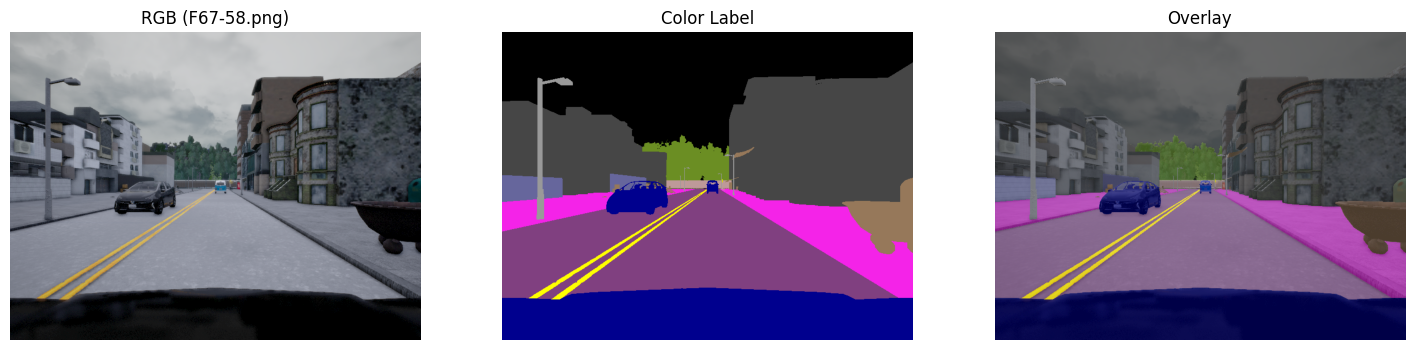

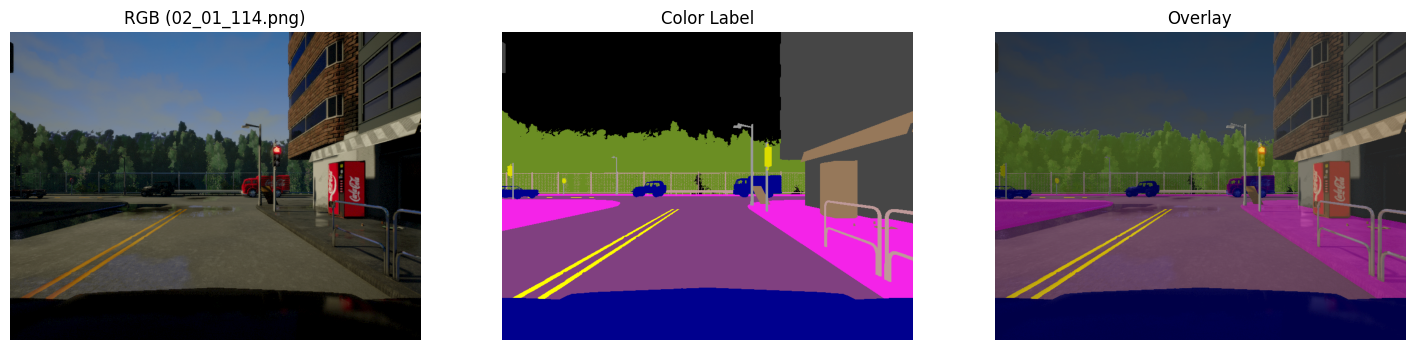

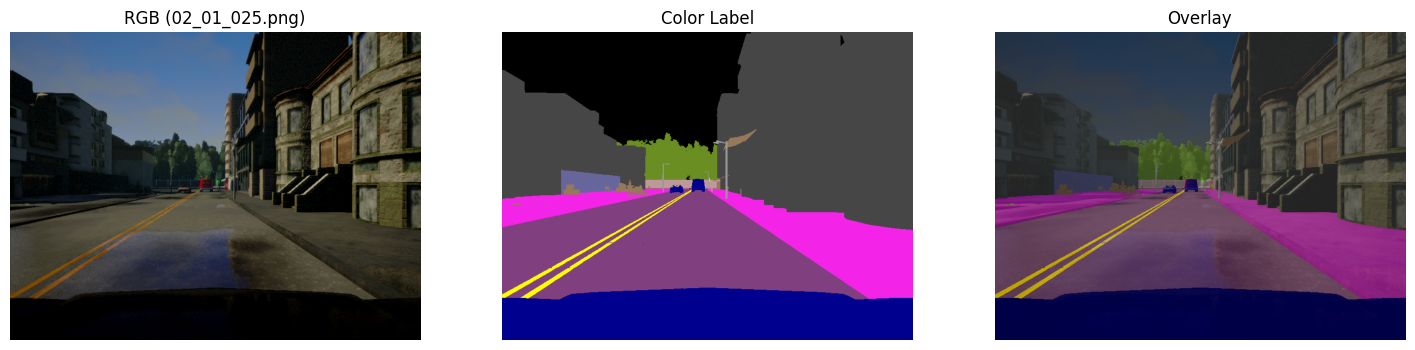

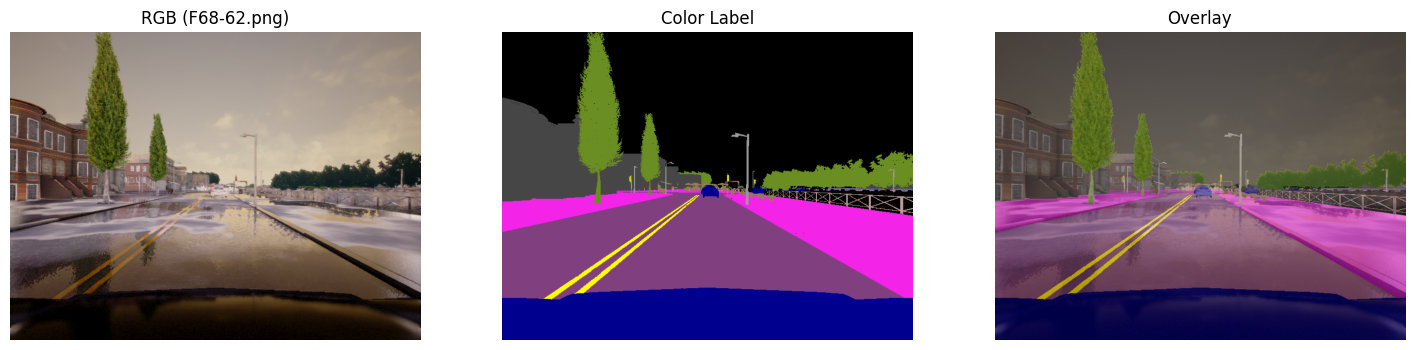

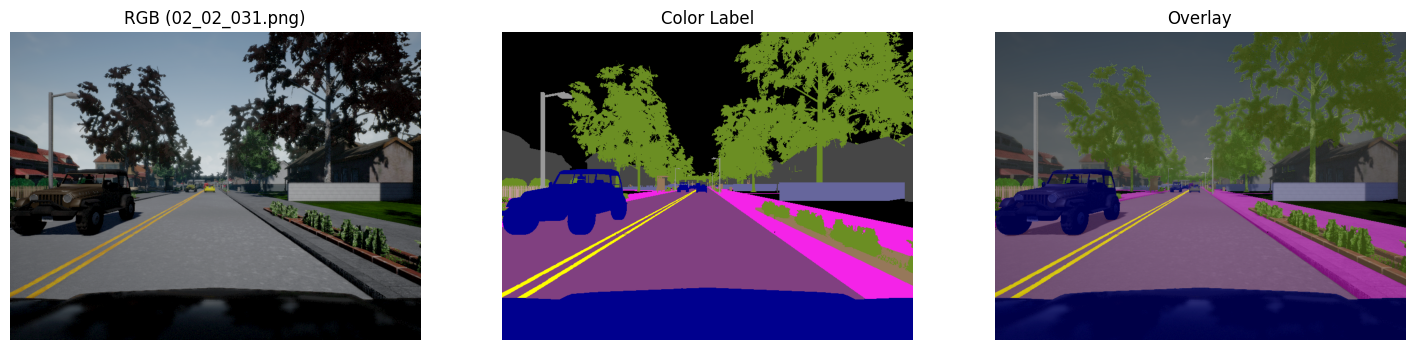

In [78]:


def visualize_random_samples(rgb_dir, label_dir, N=5, alpha=0.5):
    rgb_files = sorted(os.listdir(rgb_dir))
    label_files = sorted(os.listdir(label_dir))

    # 파일명 개수 체크
    if len(rgb_files) != len(label_files):
        print("⚠️ Warning: RGB와 Label 개수가 다릅니다!")

    # N개의 랜덤 sample 선택
    indices = random.sample(range(len(rgb_files)), N)

    for idx in indices:
        rgb_path = os.path.join(rgb_dir, rgb_files[idx])
        label_path = os.path.join(label_dir, label_files[idx])

        # Load data
        rgb = np.array(Image.open(rgb_path).convert("RGB"))
        label = load_label(label_path)
        color_label = colorize_mask(label)

        # Overlay 생성
        overlay = (rgb * (1 - alpha) + color_label * alpha).astype(np.uint8)

        # Plot
        plt.figure(figsize=(18,6))

        plt.subplot(1,3,1)
        plt.title(f"RGB ({rgb_files[idx]})")
        plt.imshow(rgb)
        plt.axis("off")

        plt.subplot(1,3,2)
        plt.title("Color Label")
        plt.imshow(color_label)
        plt.axis("off")

        plt.subplot(1,3,3)
        plt.title("Overlay")
        plt.imshow(overlay)
        plt.axis("off")

        plt.show()
visualize_random_samples(
    "/content/drive/MyDrive/Colab Notebooks/2D Segmentation/Training/RGB",
    "/content/drive/MyDrive/Colab Notebooks/2D Segmentation/Training/Label",
    N=5
)


In [79]:
import torch
import torch.nn as nn
import torch.nn.functional as F

NUM_CLASSES = 13

# ResNet Bottleneck 블록만 별도 정의 (이건 그냥 최소 단위라고 생각하자)
class Bottleneck(nn.Module):
    expansion = 4

    def __init__(self, in_channels, mid_channels,
                 stride=1, dilation=1, downsample=None):
        super().__init__()

        self.conv1 = nn.Conv2d(in_channels, mid_channels,
                               kernel_size=1, stride=1, bias=False)
        self.bn1 = nn.BatchNorm2d(mid_channels)

        self.conv2 = nn.Conv2d(
            mid_channels,
            mid_channels,
            kernel_size=3,
            stride=stride,
            padding=dilation,
            dilation=dilation,
            bias=False
        )
        self.bn2 = nn.BatchNorm2d(mid_channels)

        self.conv3 = nn.Conv2d(mid_channels,
                               mid_channels * self.expansion,
                               kernel_size=1, stride=1, bias=False)
        self.bn3 = nn.BatchNorm2d(mid_channels * self.expansion)

        self.relu = nn.ReLU(inplace=True)
        self.downsample = downsample

    def forward(self, x):
        identity = x

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)
        out = self.relu(out)

        out = self.conv3(out)
        out = self.bn3(out)

        if self.downsample is not None:
            identity = self.downsample(x)

        out += identity
        out = self.relu(out)
        return out


class MyFcnResNet50(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()

        # --------- conv1 부분 ---------
        self.conv1 = nn.Conv2d(3, 64,
                               kernel_size=7,
                               stride=2,
                               padding=3,
                               bias=False)
        self.bn1 = nn.BatchNorm2d(64)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool2d(kernel_size=3,
                                    stride=2,
                                    padding=1)

        # --------- ResNet layer1~4 (FCN_ResNet50 스타일) ---------
        # layer1: in=64, mid=64, blocks=3, stride=1, dilation=1
        self.layer1 = self._make_layer(
            in_channels=64,
            mid_channels=64,
            blocks=3,
            stride=1,
            dilations=[1, 1, 1]
        )

        # layer2: in=256, mid=128, blocks=4, 첫 블록 stride=2
        self.layer2 = self._make_layer(
            in_channels=256,
            mid_channels=128,
            blocks=4,
            stride=2,
            dilations=[1, 1, 1, 1]
        )

        # layer3: in=512, mid=256, blocks=6
        #   block0: dilation=1
        #   block1~5: dilation=2
        self.layer3 = self._make_layer(
            in_channels=512,
            mid_channels=256,
            blocks=6,
            stride=1,
            dilations=[1, 2, 2, 2, 2, 2]
        )

        # layer4: in=1024, mid=512, blocks=3
        #   block0: dilation=2
        #   block1,2: dilation=4
        self.layer4 = self._make_layer(
            in_channels=1024,
            mid_channels=512,
            blocks=3,
            stride=1,
            dilations=[2, 4, 4]
        )

        # --------- FCNHead와 동일한 classifier / aux_classifier ---------
        # main classifier: layer4(2048ch) → 512 → num_classes
        self.classifier = nn.Sequential(
            nn.Conv2d(2048, 512, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.1),
            nn.Conv2d(512, num_classes, kernel_size=1)
        )

        # aux classifier: layer3(1024ch) → 256 → num_classes
        self.aux_classifier = nn.Sequential(
            nn.Conv2d(1024, 256, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.1),
            nn.Conv2d(256, num_classes, kernel_size=1)
        )

    # layer1~4 만드는 헬퍼 (클래스 안에 포함)
    def _make_layer(self, in_channels, mid_channels,
                    blocks, stride, dilations):
        assert len(dilations) == blocks

        layers = []

        first_dilation = dilations[0]
        out_channels = mid_channels * Bottleneck.expansion

        downsample = None
        if stride != 1 or in_channels != out_channels:
            downsample = nn.Sequential(
                nn.Conv2d(in_channels, out_channels,
                          kernel_size=1,
                          stride=stride,
                          bias=False),
                nn.BatchNorm2d(out_channels),
            )

        # 첫 블록
        layers.append(
            Bottleneck(
                in_channels=in_channels,
                mid_channels=mid_channels,
                stride=stride,
                dilation=first_dilation,
                downsample=downsample
            )
        )

        # 나머지 블록들
        in_channels = out_channels
        for d in dilations[1:]:
            layers.append(
                Bottleneck(
                    in_channels=in_channels,
                    mid_channels=mid_channels,
                    stride=1,
                    dilation=d,
                    downsample=None
                )
            )

        return nn.Sequential(*layers)

    def forward(self, x):
        H, W = x.shape[2], x.shape[3]

        # backbone
        x = self.conv1(x)    # H/2
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)  # H/4

        x = self.layer1(x)   # (B, 256, H/4, W/4)
        x = self.layer2(x)   # (B, 512, H/8, W/8)
        x3 = self.layer3(x)  # (B, 1024, H/8, W/8)
        x4 = self.layer4(x3) # (B, 2048, H/8, W/8)

        # main head
        main = self.classifier(x4)  # (B, C, H/8, W/8)
        main = F.interpolate(main, size=(H, W),
                             mode="bilinear", align_corners=False)

        # aux head
        aux = self.aux_classifier(x3)  # (B, C, H/8, W/8)
        aux = F.interpolate(aux, size=(H, W),
                            mode="bilinear", align_corners=False)

        return {"out": main, "aux": aux}
        # 그냥 main만 쓰고 싶으면 return main 해도 됨

In [80]:
from torch.utils.data import Dataset
import torchvision.transforms.functional as TF
from PIL import Image
import numpy as np
import torch
import os

class SegDataset(Dataset):
    def __init__(self, rgb_dir, label_dir, train=True, transform=None,small_obj_classes=None):
        self.rgb_dir = rgb_dir
        self.label_dir = label_dir
        self.train = train
        self.transform = transform
        self.small_obj_classes = small_obj_classes

        self.rgb_files = sorted(os.listdir(rgb_dir))
        self.label_files = sorted(os.listdir(label_dir))

        assert len(self.rgb_files) == len(self.label_files), "RGB/Label 개수 불일치"

    def __len__(self):
        return len(self.rgb_files)

    def __getitem__(self, idx):
        # 파일 경로
        rgb_path = os.path.join(self.rgb_dir, self.rgb_files[idx])
        label_path = os.path.join(self.label_dir, self.label_files[idx])

        # RGB 로드
        rgb = Image.open(rgb_path).convert("RGB")
        label_raw = np.array(Image.open(label_path))

        # 라벨이 3채널이면 첫 채널 사용
        if label_raw.ndim == 3:
            label = label_raw[:, :, 0]
        else:
            label = label_raw

        # ---------- 간단한 증강: train일 때만 ----------
        if self.train:
            # 1) 랜덤 좌우 플립
            if np.random.rand() < 0.5:
                rgb = TF.hflip(rgb)
                label = np.fliplr(label).copy()

            # 2) 랜덤 크롭 (예: 512x512)
            h, w = label.shape
            crop_h, crop_w = 512, 512
            if h >= crop_h and w >= crop_w:
                top = np.random.randint(0, h - crop_h + 1)
                left = np.random.randint(0, w - crop_w + 1)
                rgb = TF.crop(rgb, top, left, crop_h, crop_w)
                label = label[top:top+crop_h, left:left+crop_w]
            # (너무 복잡하게 안 가고, 단순 예시 수준으로)

        # To Tensor
        rgb = TF.to_tensor(rgb)                        # → (3,H,W), float32, [0,1]
        label = torch.tensor(label, dtype=torch.long)  # → (H,W), long

        return rgb, label


In [81]:
from torch.utils.data import DataLoader
# 작은 객체 클래스 ID 리스트 정의
small_obj_ids = [4, 6, 12]  # Pedestrians, RoadLines, TrafficSigns

# Dataset 생성
train_dataset = SegDataset(
    rgb_dir=train_rgb_dir,
    label_dir=train_label_dir,
    transform=None,
    small_obj_classes=small_obj_ids
)

val_dataset = SegDataset(
    rgb_dir=val_rgb_dir,
    label_dir=val_label_dir,
    transform=None,
    small_obj_classes=small_obj_ids
)


In [82]:
import torch
import torch.nn.functional as F
import numpy as np

def train_seg(model, data_loader, optimizer, device, class_weights=None):
    model.train()
    trn_loss = 0.0
    total_pixels = 0
    correct_pixels = 0

    for i, (x, y) in enumerate(data_loader):
        x = x.to(device)           # (B, 3, H, W)
        y = y.to(device)           # (B, H, W)

        optimizer.zero_grad()

        # forward
        out_dict = model(x)
        main_logits = out_dict["out"]          # (B, C, H, W)
        aux_logits  = out_dict["aux"]          # (B, C, H, W)

        if class_weights is not None:
            main_loss = F.cross_entropy(main_logits, y,
                                        weight=class_weights,
                                        reduction='mean')
            aux_loss  = F.cross_entropy(aux_logits,  y,
                                        weight=class_weights,
                                        reduction='mean')
        else:
            main_loss = F.cross_entropy(main_logits, y, reduction='mean')
            aux_loss  = F.cross_entropy(aux_logits,  y, reduction='mean')

        loss = main_loss + 0.4 * aux_loss

        loss.backward()
        optimizer.step()

        trn_loss += loss.item()

        # pixel accuracy 계산
        with torch.no_grad():
            preds = main_logits.argmax(dim=1)  # (B, H, W)
            correct = (preds == y).sum().item()
            pixels  = y.numel()
            correct_pixels += correct
            total_pixels   += pixels

    # 🔹 loss 평균은 "step 수" 기준으로 나누는 게 자연스러움
    avg_trn_loss = trn_loss / len(data_loader)
    trn_acc = correct_pixels / total_pixels
    return avg_trn_loss, trn_acc


def evaluate_seg(model, data_loader, device, class_weights=None):
    model.eval()
    eval_loss = 0.0
    total_pixels = 0
    correct_pixels = 0

    with torch.no_grad():
        for i, (x, y) in enumerate(data_loader):
            x = x.to(device)
            y = y.to(device)

            out_dict = model(x)
            main_logits = out_dict["out"]
            aux_logits  = out_dict["aux"]

            if class_weights is not None:
                main_loss = F.cross_entropy(main_logits, y,
                                            weight=class_weights,
                                            reduction='mean')
                aux_loss  = F.cross_entropy(aux_logits,  y,
                                            weight=class_weights,
                                            reduction='mean')
            else:
                main_loss = F.cross_entropy(main_logits, y, reduction='mean')
                aux_loss  = F.cross_entropy(aux_logits,  y, reduction='mean')

            loss = main_loss + 0.4 * aux_loss


            eval_loss += loss.item()

            preds = main_logits.argmax(dim=1)
            correct = (preds == y).sum().item()
            pixels  = y.numel()
            correct_pixels += correct
            total_pixels   += pixels

    avg_eval_loss = eval_loss / len(data_loader)
    eval_acc = correct_pixels / total_pixels
    return avg_eval_loss, eval_acc


In [83]:
import torch
from torch.utils.data import DataLoader, random_split


# -------------------------------
# 전체 세그 데이터셋
# -------------------------------
full_dataset = SegDataset(train_rgb_dir, train_label_dir, train=True)

# train : val = 8:2
train_size = int(0.8 * len(full_dataset))
val_size   = len(full_dataset) - train_size

g = torch.Generator().manual_seed(SEED)
trn_dset, val_dset = random_split(full_dataset, [train_size, val_size], generator=g)

print(f"train: {len(trn_dset)}, val: {len(val_dset)}")

# -------------------------------
# DataLoader 설정
# -------------------------------
BATCH_SIZE = 4

# Validation 데이터셋
test_dataset = SegDataset(val_rgb_dir, val_label_dir, train=False)

trn_loader = DataLoader(trn_dset,
                        batch_size=BATCH_SIZE,
                        shuffle=True,
                        drop_last=False)

val_loader = DataLoader(val_dset,
                        batch_size=BATCH_SIZE,
                        shuffle=False,
                        drop_last=False)

test_loader = DataLoader(test_dataset,
                         batch_size=BATCH_SIZE,
                         shuffle=False)

print("DataLoader 준비 완료 ✅")


train: 800, val: 200
DataLoader 준비 완료 ✅


RGB images: 1000
Label images: 1000

Unique image sizes: {(800, 600)}


Counting class pixels: 100%|██████████| 1000/1000 [00:17<00:00, 56.10it/s]



Class pixel ratio (%):
Class 0: 28.237%
Class 1: 11.804%
Class 2: 0.781%
Class 3: 1.202%
Class 4: 0.006%
Class 5: 0.490%
Class 6: 0.744%
Class 7: 19.667%
Class 8: 7.973%
Class 9: 11.463%
Class 10: 16.661%
Class 11: 0.893%
Class 12: 0.081%


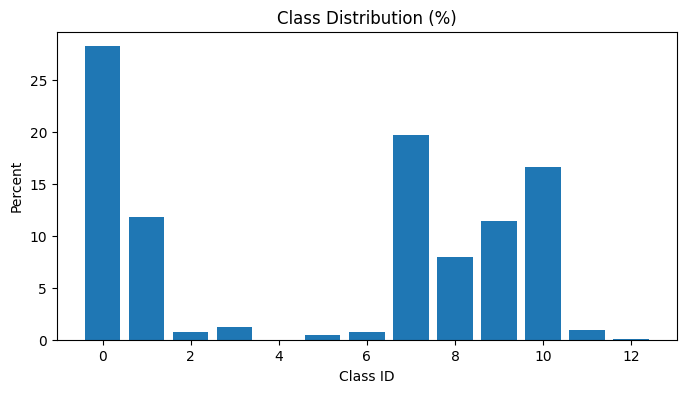

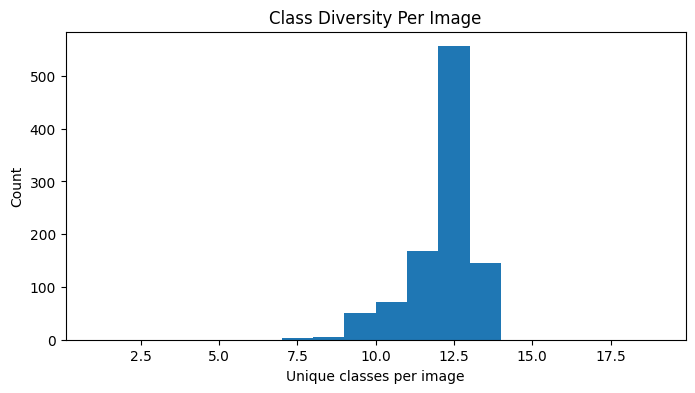

Average classes per image: 11.644

Suggested class weights: [ 3.78524881  7.73363578 36.45977713 31.73269781 50.33929484 40.65070114
 36.94042247  5.09896033 10.51955619  7.9175004   5.84452258 35.0682095
 48.56180473]

All label values in dataset: [np.uint8(0), np.uint8(1), np.uint8(2), np.uint8(3), np.uint8(4), np.uint8(5), np.uint8(6), np.uint8(7), np.uint8(8), np.uint8(9), np.uint8(10), np.uint8(11), np.uint8(12)]


In [84]:
import torch
import torch.optim as optim

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = MyFcnResNet50(num_classes=13).to(device)  #모델 구조 인스턴스화

LR = 2e-4  #학습률 0.0002로 설정하기
my_opt = optim.Adam(model.parameters(), lr=LR)

class_weights_np = run_full_eda(train_rgb_dir, train_label_dir) #NumPy 배열 형태로 미리 계산된 각 클래스별 가중치
class_weights = torch.tensor(class_weights_np, dtype=torch.float32, device=device)  #클래스 가중치 설정

In [ ]:
import time
import os

N_EPOCH = 10
best_val_loss = float('inf')
tolerance = 0
MAX_TOL = 5
model_path = 'models_seg'

if not os.path.exists(model_path):
    os.makedirs(model_path)

for epoch in range(N_EPOCH):
    start_time = time.time()

    trn_loss, trn_acc = train_seg(model=model,
                                data_loader=trn_loader,
                                optimizer=my_opt,
                                device=device,
                                class_weights=class_weights)

    val_loss, val_acc = evaluate_seg(model=model,
                                    data_loader=val_loader,
                                    device=device,
                                    class_weights=class_weights)

    end_time = time.time()
    epoch_mins, epoch_secs = epoch_time(start_time, end_time)

    print(f'Epoch: {epoch+1:02} | Time: {epoch_mins}m {epoch_secs}s')
    print(f'\tTrn Loss: {trn_loss:.4f} | Trn Acc: {100*trn_acc:.2f}%')
    print(f'\tVal Loss: {val_loss:.4f} | Val Acc: {100*val_acc:.2f}%')

    if val_loss < best_val_loss:
        print(f'\tval_loss({val_loss:.4f}) < best_val_loss({best_val_loss:.4f}) → 모델 저장')
        best_val_loss = val_loss
        tolerance = 0
        torch.save(model.state_dict(), f'{model_path}/my_fcnresnet50_251121.pt')
    else:
        tolerance += 1
        print(f'\tval_loss({val_loss:.4f}) >= best_val_loss({best_val_loss:.4f}) → tolerance={tolerance}')

    if tolerance >= MAX_TOL:
        print(f'>> tolerance={tolerance}. Stop training!\n')
        break


Epoch: 01 | Time: 4m 7s
	Trn Loss: 1.3377 | Trn Acc: 78.62%
	Val Loss: 0.9253 | Val Acc: 87.24%
	val_loss(0.9253) < best_val_loss(inf) → 모델 저장
Epoch: 02 | Time: 4m 6s
	Trn Loss: 0.7616 | Trn Acc: 87.35%
	Val Loss: 0.6283 | Val Acc: 89.50%
	val_loss(0.6283) < best_val_loss(0.9253) → 모델 저장


In [ ]:
import numpy as np
import torch

def evaluate_model(model, dataloader, num_classes=NUM_CLASSES, device="cuda"):
    model.eval()
    model.to(device)

    conf_matrix = np.zeros((num_classes, num_classes), dtype=np.int64)
    total_correct = 0
    total_pixels = 0

    with torch.no_grad():
        for images, masks in dataloader:
            images = images.to(device)
            masks  = masks.to(device)  # (B,H,W)

            # ★ 네 모델은 dict로 반환하므로 이렇게 받아야 함
            out_dict = model(images)
            outputs = out_dict["out"]     # (B,C,H,W)

            preds = torch.argmax(outputs, dim=1)  # (B,H,W)

            # Pixel Accuracy
            total_correct += (preds == masks).sum().item()
            total_pixels  += masks.numel()

            # Confusion Matrix 업데이트
            preds_flat = preds.view(-1).cpu().numpy()
            masks_flat = masks.view(-1).cpu().numpy()

            for t, p in zip(masks_flat, preds_flat):
                if t < num_classes:
                    conf_matrix[t, p] += 1

    # Pixel Accuracy
    pixel_acc = total_correct / total_pixels

    # IoU per class
    ious = []
    for cls in range(num_classes):
        tp = conf_matrix[cls, cls]
        fp = conf_matrix[:, cls].sum() - tp
        fn = conf_matrix[cls, :].sum() - tp

        denom = tp + fp + fn
        if denom == 0:
            iou = float("nan")
        else:
            iou = tp / denom

        ious.append(iou)

    # mIoU
    valid_ious = [x for x in ious if not np.isnan(x)]
    miou = np.mean(valid_ious) if len(valid_ious) > 0 else 0.0

    return pixel_acc, ious, miou, conf_matrix




best_model_path = f'{model_path}/my_fcnresnet50_251121.pt'
model.load_state_dict(torch.load(best_model_path, map_location=device))

pixel_acc, ious, miou, confmat = evaluate_model(model, val_loader, NUM_CLASSES, device)


print(f"Pixel Accuracy: {pixel_acc*100:.2f}%")
print(f"mIoU: {miou*100:.2f}%")

class_names = [
    "None",
    "Buildings",
    "Fences",
    "Other",
    "Pedestrians",
    "Poles",
    "RoadLines",
    "Roads",
    "Sidewalks",
    "Vegetation",
    "Vehicles",
    "Walls",
    "TrafficSigns",
]

for i, iou in enumerate(ious):
    if np.isnan(iou):
        print(f"Class {i:2d} ({class_names[i]:12s}): IoU = N/A (not present)")
    else:
        print(f"Class {i:2d} ({class_names[i]:12s}): IoU = {iou*100:5.2f}%")


In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt

def visualize_val_samples(model, dataset, indices, device="cuda"):
    # device 문자열/torch.device 둘 다 허용
    if isinstance(device, str):
        device = torch.device(device)

    model.eval()
    model.to(device)

    for idx in indices:
        # dataset은 SegDataset 또는 random_split으로 나온 Subset
        rgb, gt = dataset[idx]          # rgb: (3,H,W), gt: (H,W)
        img = rgb.unsqueeze(0).to(device)  # (1,3,H,W)

        with torch.no_grad():
            out_dict = model(img)       # dict: {"out": main, "aux": aux}
            logits = out_dict["out"]    # (1,C,H,W)
            pred = torch.argmax(logits, dim=1)[0].cpu().numpy()  # (H,W)

        gt_np = gt.numpy()                                # (H,W)
        rgb_np = (rgb.numpy().transpose(1, 2, 0) * 255).astype(np.uint8)  # (H,W,3)

        # 여기서 colorize_mask 사용 (네가 위에서 정의한 함수)
        gt_color = colorize_mask(gt_np)      # (H,W,3)
        pred_color = colorize_mask(pred)     # (H,W,3)

        # overlay_gt   = (0.6*rgb_np + 0.4*gt_color).astype(np.uint8)
        overlay_pred = (0.6*rgb_np + 0.4*pred_color).astype(np.uint8)

        plt.figure(figsize=(16,6))
        plt.subplot(1,4,1); plt.title("원본 RGB");       plt.imshow(rgb_np);      plt.axis("off")
        plt.subplot(1,4,2); plt.title("val_label");        plt.imshow(gt_color);  plt.axis("off")
        plt.subplot(1,4,3); plt.title("예측"); plt.imshow(pred_color);plt.axis("off")
        plt.subplot(1,4,4); plt.title("Pred");      plt.imshow(overlay_pred);  plt.axis("off")
        plt.show()

best_model_path = f'{model_path}/my_fcnresnet50_251121.pt'
model.load_state_dict(torch.load(best_model_path, map_location=device))

num_samples = 5
rand_indices = random.sample(range(len(test_dataset)), num_samples)

visualize_val_samples(model, test_dataset, indices=rand_indices, device=device)
